In [1]:
!pip install -q torchinfo
!pip install -q jiwer
!pip install -q torch
!pip install -q torchvision
!pip install -q PIL
!pip install -q opencv-python
!pip install -q Pillow
!pip install -q pandas
!pip install -q matplotlib
!pip install -q scipy


[notice] A new release of pip is available: 24.2 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 24.2 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 24.2 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 24.2 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Could not find a version that satisfies the requirement PIL (from versions: none)

[notice] A new release of pip is available: 24.2 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for PIL

[notice] A new release of pip is available: 24.2 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 24.2 -> 25.1.1
[notice] To update, run: python.exe -m pip install --up

In [2]:
!pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118


[notice] A new release of pip is available: 24.2 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import os
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from jiwer import wer
from PIL import Image
from scipy.ndimage import gaussian_filter

# Vocab

In [4]:
class Vocab():
    def __init__(self, chars):
        self.blank = 0
        self.pad = 1
        self.go = 2
        self.eos = 3
        self.mask_token = 4

        self.chars = chars

        self.c2i = {c:i+5 for i, c in enumerate(chars)}

        self.i2c = {i+5:c for i, c in enumerate(chars)}

        self.i2c[0] = '<blank>'        
        self.i2c[1] = '<pad>'
        self.i2c[2] = '<sos>'
        self.i2c[3] = '<eos>'
        self.i2c[4] = '*'

    def encode(self, chars):
        return [self.c2i[c] for c in chars] 

    def decode(self, ids):
        if isinstance(ids, np.ndarray):
          ids = ids.tolist()
        
        result = []
        prev = None
        for i in ids:
            if i == self.blank:
                continue
            if i != prev and i > 4:
                result.append(i)
            prev = i
            
        sent = ''.join([self.i2c[i] for i in result if i in self.i2c])
        return sent 
      
    def __len__(self):
        return len(self.c2i) + 5

    def batch_decode(self, arr):
         return [self.decode(ids) for ids in arr]

    def __str__(self):
        return self.chars

vocab = Vocab('aAàÀảẢãÃáÁạẠăĂằẰẳẲẵẴắẮặẶâÂầẦẩẨẫẪấẤậẬbBcCdDđĐeEèÈẻẺẽẼéÉẹẸêÊềỀểỂễỄếẾệỆfFgGhHiIìÌỉỈĩĨíÍịỊjJkKlLmMnNoOòÒỏỎõÕóÓọỌôÔồỒổỔỗỖốỐộỘơƠờỜởỞỡỠớỚợỢpPqQrRsStTuUùÙủỦũŨúÚụỤưƯừỪửỬữỮứỨựỰvVwWxXyYỳỲỷỶỹỸýÝỵỴzZ0123456789!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~ ')
vocab_size = len(vocab)

# Model

In [5]:
class CRNN_RNN(nn.Module):
    def __init__(self, vocab_size, img_channels=1, rnn_hidden=512):
        super(CRNN_RNN, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(img_channels, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout(0.1),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout(0.1),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout(0.1),
            nn.Conv2d(256, 256, 3, stride=(2, 2), padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.Dropout(0.1),
            nn.Conv2d(256, 512, 3, stride=(2, 1), padding=1), nn.BatchNorm2d(512), nn.ReLU(), nn.Dropout(0.1),
            nn.Conv2d(512, 512, 3, stride=(2, 1), padding=1), nn.BatchNorm2d(512), nn.ReLU(), nn.Dropout(0.2),
            nn.Conv2d(512, 1024, 3, padding=1), nn.BatchNorm2d(1024), nn.ReLU(), nn.Dropout(0.2)
        )
        self.rnn = nn.RNN(input_size=1024, hidden_size=rnn_hidden, num_layers=2, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(rnn_hidden, vocab_size)

    def forward(self, x):
        features = self.cnn(x)
        b, c, h, w = features.size()
        features = features.permute(0, 3, 1, 2).contiguous().view(b, w, c * h)
        rnn_out = self.rnn(features)[0]
        rnn_out = self.dropout(rnn_out)
        output = self.classifier(rnn_out)
        return output.permute(1, 0, 2)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model_path = "./trained_model/best_model_line.pth"
model = CRNN_RNN(vocab_size=len(vocab)).to(device)
model.load_state_dict(torch.load(best_model_path))

<All keys matched successfully>

# Image Preprocessing

In [7]:
def process(img_path):
    img = cv2.imread(img_path, 0)
    if img is None:
        return None
    img_h, img_w = img.shape
    img = cv2.resize(img, (640, img_h), interpolation=cv2.INTER_AREA)
    kernel = np.ones((1, 1), np.uint8)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    img = clahe.apply(img)
    img = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 5)
    img = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel)
    img = cv2.dilate(img, kernel, iterations=1)
    return img

def preprocess_image(image_path, label_len, img_h=64, char_w=32):
    valid_img = True
    img = process(image_path)

    img_w = label_len * char_w
    img = cv2.resize(img, (img_w, img_h), interpolation=cv2.INTER_AREA)

    img = np.expand_dims(img, axis=0) / 255.0
    return torch.tensor(img, dtype=torch.float32)

# Estimate the number of characters in image

In [ ]:
def estimate_character_count_with_spaces(image_path, avg_char_area=100, threshold=0.5, space_width_factor=0.3):
    img = Image.open(image_path).convert('L')
    img_array = np.array(img) / 255.0 

    img_array = gaussian_filter(img_array, sigma=1)

    binary = (img_array < threshold).astype(int)  
    total_char_pixels = np.sum(binary)

    horizontal_projection = np.sum(binary, axis=1)
    line_threshold = np.mean(horizontal_projection) + np.std(horizontal_projection)
    lines_with_text = horizontal_projection > line_threshold

    vertical_projection = np.sum(binary[lines_with_text], axis=0)

    non_zero_columns = np.where(vertical_projection > 0)[0]
    if len(non_zero_columns) == 0:
        return 0 
    x_start = non_zero_columns[0]
    x_end = non_zero_columns[-1]

    vertical_projection = vertical_projection[x_start:x_end + 1]

    char_widths = []
    in_char_region = False
    current_width = 0
    for val in vertical_projection:
        if val > 0:
            current_width += 1
            in_char_region = True
        else:
            if in_char_region and current_width > 0:
                char_widths.append(current_width)
                current_width = 0
            in_char_region = False
    if in_char_region and current_width > 0:
        char_widths.append(current_width)

    avg_char_width = np.mean(char_widths) if char_widths else 5  
    min_space_width = avg_char_width * space_width_factor

    char_regions = 0  
    space_regions = 0  
    in_char_region = False
    space_width = 0 

    for val in vertical_projection:
        if val > 0:  
            if not in_char_region:
                char_regions += 1 
                if space_width >= min_space_width:  
                    space_regions += 1
                space_width = 0 
            in_char_region = True
        else:  
            if in_char_region:
                in_char_region = False
            space_width += 1  

    if space_width >= min_space_width:
        space_regions += 1

    estimated_chars_area = total_char_pixels / avg_char_area

    if char_regions < estimated_chars_area * 0.5: 
        total_chars = round(estimated_chars_area)
    else:
        total_chars = min(round(estimated_chars_area), char_regions)
    total_spaces = space_regions
    total = total_chars + total_spaces

    print(f"Tổng số pixel chữ: {total_char_pixels}")
    print(f"Ước lượng ký tự chữ từ diện tích: {estimated_chars_area:.2f}")
    print(f"Số ký tự chữ từ phép chiếu: {char_regions}")
    print(f"Độ rộng trung bình của ký tự: {avg_char_width:.2f} pixel")
    print(f"Ngưỡng min_space_width: {min_space_width:.2f} pixel")
    print(f"Số ký tự khoảng cách: {space_regions}")
    print(f"Vùng phân tích: cột {x_start} đến cột {x_end}")

    return total

# Predict function

In [ ]:
def predict_image(image_path, model, vocab, device, label_len):
    image = preprocess_image(image_path, label_len)
    if image is None:
        raise ValueError(f"preprocess_image trả về None cho ảnh {image_path}")
    
    image = image.unsqueeze(0).to(device)  

    model.eval()
    with torch.no_grad():
        output = model(image)  
        log_probs = F.log_softmax(output, dim=2)
        pred_indices = log_probs.argmax(dim=2)  
        pred_indices = pred_indices.squeeze(1).cpu().numpy() 

        # CTC decoding
        prev = -1
        collapsed = []
        for idx in pred_indices:
            if idx != prev and idx != vocab.blank:
                collapsed.append(idx)
            prev = idx

        predicted_text = vocab.decode(collapsed)
        print(f"Predicted dictionary: {repr(collapsed)}")
    return predicted_text

# Testing

Tổng số pixel chữ: 34823
Ước lượng ký tự chữ từ diện tích: 13.39
Số ký tự chữ từ phép chiếu: 17
Độ rộng trung bình của ký tự: 58.59 pixel
Ngưỡng min_space_width: 29.29 pixel
Số ký tự khoảng cách: 5
Vùng phân tích: cột 149 đến cột 1760
Ước lượng tổng số ký tự (bao gồm khoảng cách): 18


Predicted dictionary: [np.int64(98), np.int64(5), np.int64(79), np.int64(233), np.int64(146), np.int64(79), np.int64(69), np.int64(99), np.int64(233), np.int64(46), np.int64(153), np.int64(99), np.int64(75)]
Predicted text: 'Mai Tiến Dũng'


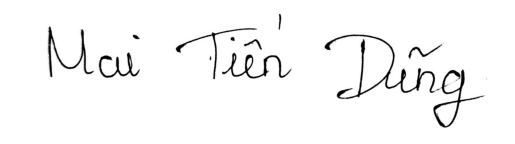

In [ ]:
image_path = "./data/Self-handwritten/maitiendung2.jpg"
num_chars = estimate_character_count_with_spaces(image_path, avg_char_area=2600, threshold=0.5, space_width_factor=0.5)
print(f"Ước lượng tổng số ký tự (bao gồm khoảng cách): {num_chars}")
predicted_text = predict_image(image_path, model, vocab, device, label_len = num_chars)
print(f"Predicted text: {repr(predicted_text)}")

img = Image.open(image_path)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

Tổng số pixel chữ: 19277
Ước lượng ký tự chữ từ diện tích: 17.52
Số ký tự chữ từ phép chiếu: 11
Độ rộng trung bình của ký tự: 64.09 pixel
Ngưỡng min_space_width: 32.05 pixel
Số ký tự khoảng cách: 3
Vùng phân tích: cột 93 đến cột 1163
Ước lượng tổng số ký tự (bao gồm khoảng cách): 14
Predicted dictionary: [np.int64(145), np.int64(81), np.int64(99), np.int64(77), np.int64(233), np.int64(145), np.int64(61), np.int64(147), np.int64(233), np.int64(47), np.int64(37), np.int64(145), np.int64(233), np.int64(99), np.int64(159), np.int64(133), np.int64(43)]
Predicted text: 'tình têu đất nước'


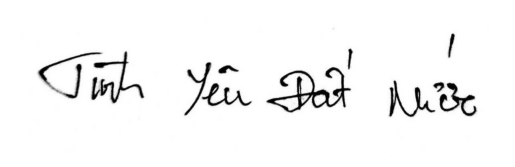

In [ ]:
image_path = r"./data/Self-handwritten/tinhyeudatnuoc.png"
num_chars = estimate_character_count_with_spaces(image_path, avg_char_area=1100, threshold=0.5, space_width_factor=0.5)
print(f"Ước lượng tổng số ký tự (bao gồm khoảng cách): {num_chars}")
predicted_text = predict_image(image_path, model, vocab, device, label_len = num_chars)
print(f"Predicted text: {repr(predicted_text)}")

img = Image.open(image_path)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()